In [1]:
pip install pyspark faker scikit-learn matplotlib seaborn

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
    --------------------------------------- 0.0/2.0 MB 1.3 MB/s eta 0:00:02
   - -------------------------------------- 0.1/2.0 MB 919.0 kB/s eta 0:00:03
   -- ------------------------------------- 0.1/2.0 MB 901.1 kB/s eta 0:00:03
   ---- ----------------------------------- 0.2/2.0 MB 1.1 MB/s eta 0:00:02
   ----- ---------------------------------- 0.3/2.0 MB 1.1 MB/s eta 0:00:02
   ------ --------------------------------- 0.3/2.0 MB 1.3 MB/s eta 0:00:02
   ------- -------------------------------- 0.4/2.0 MB 1.3 MB/s eta 0:00:02
   -------- ------------------------------- 0.4/2.0 MB 1.2 MB/s eta 0:00:02
   --------- ------------------------------ 0.5/2.0 MB 1.2 MB/s eta 0:00:02
   ---------- ----------------------------- 0.5/2.0 MB 1.2 MB/s eta 0:00:02
   ------------ --------------------------- 0.6/2.0 MB 1.2 MB/s eta 0:00:02
   ------------- -----

In [2]:
# Install required packages (run once)
# !pip install pyspark faker mlflow scikit-learn pandas numpy matplotlib seaborn

import warnings
warnings.filterwarnings('ignore')

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# PySpark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

# SparkML
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer, VectorAssembler, StandardScaler,
    OneHotEncoder, Tokenizer, HashingTF, IDF
)
from pyspark.ml.classification import (
    RandomForestClassifier, LogisticRegression, GBTClassifier
)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

print('✅ All imports successful!')

✅ All imports successful!


In [3]:
# Initialize Spark Session
spark = SparkSession.builder \
    .appName('TicketPriorityPrediction') \
    .config('spark.driver.memory', '4g') \
    .config('spark.sql.shuffle.partitions', '50') \
    .getOrCreate()

spark.sparkContext.setLogLevel('ERROR')
print(f'✅ Spark version: {spark.version}')
print(f'   App Name   : {spark.sparkContext.appName}')

✅ Spark version: 3.5.1
   App Name   : TicketPriorityPrediction


In [4]:
random.seed(42)
np.random.seed(42)

NUM_RECORDS = 10000

# ---------- Vocabulary pools ----------
channels      = ['email', 'chat', 'web', 'call']
products      = ['SmartTV', 'Laptop', 'Router', 'Printer', 'Tablet', 'SmartPhone', 'Headphones']
regions       = ['North', 'South', 'East', 'West', 'Central']
tiers         = ['Bronze', 'Silver', 'Gold', 'Platinum']
categories    = ['Billing', 'Technical', 'Delivery', 'Returns', 'Account', 'Product Defect', 'General']
priorities    = ['Low', 'Medium', 'High', 'Critical']

# Sample ticket texts per category
ticket_texts = {
    'Billing'       : [
        'I was charged twice for my last order.',
        'My invoice shows an incorrect amount.',
        'I need a refund for the overcharge on my account.',
        'My payment failed but money was deducted.',
    ],
    'Technical'     : [
        'My device is not connecting to WiFi after the update.',
        'The application crashes every time I open it.',
        'Screen flickering issue on my SmartTV.',
        'Cannot login, getting error 503.',
    ],
    'Delivery'      : [
        'My order has not arrived after 10 days.',
        'Package was marked delivered but I never received it.',
        'Wrong item was shipped to me.',
    ],
    'Returns'       : [
        'I want to return a defective product.',
        'Return request pending for 2 weeks, no update.',
        'Refund not received after returning the item.',
    ],
    'Account'       : [
        'I cannot reset my password.',
        'Account locked after multiple login attempts.',
        'Two-factor authentication code not received.',
    ],
    'Product Defect': [
        'Device stopped working within one week of purchase.',
        'Battery drains within 30 minutes. URGENT replacement needed!',
        'Critical hardware failure — device completely unresponsive.',
    ],
    'General'       : [
        'I have a general query about my subscription.',
        'How do I upgrade my plan?',
        'Where can I find the user manual?',
    ],
}

urgent_phrases = ['urgent', 'critical', 'asap', 'immediately', 'broken', 'failure', 'not working', 'emergency']

def assign_priority(row):
    """Rule-based priority assignment to create realistic label distribution."""
    score = 0
    if row['customer_tier'] == 'Platinum': score += 3
    elif row['customer_tier'] == 'Gold':   score += 2
    elif row['customer_tier'] == 'Silver': score += 1
    
    if row['issue_category'] in ['Technical', 'Product Defect']: score += 2
    elif row['issue_category'] in ['Billing', 'Returns']:        score += 1
    
    if row['sentiment_score'] < -0.5: score += 2
    elif row['sentiment_score'] < 0:  score += 1
    
    if row['contains_urgent_words']: score += 2
    if row['response_time_hours'] > 48: score += 1
    if row['num_previous_tickets'] > 5: score += 1
    
    score += random.randint(-1, 1)   # add some noise
    
    if score >= 8:   return 'Critical'
    elif score >= 5: return 'High'
    elif score >= 2: return 'Medium'
    else:            return 'Low'

# ---------- Build rows ----------
rows = []
base_date = datetime(2023, 1, 1)

for i in range(NUM_RECORDS):
    category = random.choice(categories)
    text     = random.choice(ticket_texts[category])
    sentiment = round(random.uniform(-1.0, 1.0), 2)
    contains_urgent = int(any(w in text.lower() for w in urgent_phrases))
    
    row = {
        'ticket_id'            : f'TKT-{10000 + i}',
        'created_at'           : (base_date + timedelta(days=random.randint(0, 364))).strftime('%Y-%m-%d'),
        'channel'              : random.choice(channels),
        'product'              : random.choice(products),
        'region'               : random.choice(regions),
        'customer_tier'        : random.choices(tiers, weights=[40, 30, 20, 10])[0],
        'issue_category'       : category,
        'ticket_text'          : text,
        'response_time_hours'  : round(random.expovariate(1/24), 1),
        'num_previous_tickets' : random.randint(0, 20),
        'sentiment_score'      : sentiment,
        'contains_urgent_words': contains_urgent,
    }
    row['priority_label'] = assign_priority(row)
    rows.append(row)

pdf = pd.DataFrame(rows)
print(f'✅ Generated {len(pdf):,} synthetic tickets')
pdf.head(3)

✅ Generated 10,000 synthetic tickets


,ticket_id,created_at,channel,product,region,customer_tier,issue_category,ticket_text,response_time_hours,num_previous_tickets,sentiment_score,contains_urgent_words,priority_label
0,TKT-10000,2023-05-21,chat,Laptop,South,Gold,Product Defect,Device stopped working within one week of purc...,27.1,17,-0.95,0,High
1,TKT-10001,2023-02-17,chat,Laptop,Central,Silver,Account,Account locked after multiple login attempts.,19.8,20,-0.94,0,High
2,TKT-10002,2023-10-29,web,Headphones,North,Gold,Account,Account locked after multiple login attempts.,4.2,13,-0.56,0,High


In [5]:
# Save synthetic data as CSV
pdf.to_csv('support_tickets.csv', index=False)
print('✅ Dataset saved to support_tickets.csv')

# Priority distribution
print('\nPriority distribution:')
print(pdf['priority_label'].value_counts())

✅ Dataset saved to support_tickets.csv

Priority distribution:
priority_label
Medium      5345
High        2796
Low         1469
Critical     390
Name: count, dtype: int64


In [6]:
# Load CSV into Spark DataFrame
sdf = spark.read.csv('support_tickets.csv', header=True, inferSchema=True)

print(f'✅ Loaded {sdf.count():,} rows | {len(sdf.columns)} columns')
sdf.printSchema()

✅ Loaded 10,000 rows | 13 columns
root
 |-- ticket_id: string (nullable = true)
 |-- created_at: date (nullable = true)
 |-- channel: string (nullable = true)
 |-- product: string (nullable = true)
 |-- region: string (nullable = true)
 |-- customer_tier: string (nullable = true)
 |-- issue_category: string (nullable = true)
 |-- ticket_text: string (nullable = true)
 |-- response_time_hours: double (nullable = true)
 |-- num_previous_tickets: integer (nullable = true)
 |-- sentiment_score: double (nullable = true)
 |-- contains_urgent_words: integer (nullable = true)
 |-- priority_label: string (nullable = true)



In [7]:
# ---- Exploratory checks ----
print('=== Sample rows ===')
sdf.show(3, truncate=60)

print('\n=== Null counts ===')
sdf.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in sdf.columns]).show()

print('\n=== Priority label distribution ===')
sdf.groupBy('priority_label').count().orderBy('count', ascending=False).show()

=== Sample rows ===
+---------+----------+-------+----------+-------+-------------+--------------+---------------------------------------------------+-------------------+--------------------+---------------+---------------------+--------------+
|ticket_id|created_at|channel|   product| region|customer_tier|issue_category|                                        ticket_text|response_time_hours|num_previous_tickets|sentiment_score|contains_urgent_words|priority_label|
+---------+----------+-------+----------+-------+-------------+--------------+---------------------------------------------------+-------------------+--------------------+---------------+---------------------+--------------+
|TKT-10000|2023-05-21|   chat|    Laptop|  South|         Gold|Product Defect|Device stopped working within one week of purchase.|               27.1|                  17|          -0.95|                    0|          High|
|TKT-10001|2023-02-17|   chat|    Laptop|Central|       Silver|       Account|  

In [8]:
# ---- Feature Engineering ----

# 1. Ticket text length
sdf = sdf.withColumn('text_length', F.length(F.col('ticket_text')))

# 2. Month extracted from created_at
sdf = sdf.withColumn('created_month', F.month(F.to_date(F.col('created_at'), 'yyyy-MM-dd')))

# 3. Clip response_time_hours to max 168 hours (1 week)
sdf = sdf.withColumn(
    'response_time_hours',
    F.when(F.col('response_time_hours') > 168, 168).otherwise(F.col('response_time_hours'))
)

# 4. Tier rank (ordinal)
tier_map = {'Bronze': 1, 'Silver': 2, 'Gold': 3, 'Platinum': 4}
mapping_expr = F.create_map([F.lit(x) for kv in tier_map.items() for x in kv])
sdf = sdf.withColumn('tier_rank', mapping_expr[F.col('customer_tier')])

print('✅ Feature engineering complete')
sdf.select('ticket_id', 'text_length', 'created_month', 'tier_rank', 'priority_label').show(5)

✅ Feature engineering complete
+---------+-----------+-------------+---------+--------------+
|ticket_id|text_length|created_month|tier_rank|priority_label|
+---------+-----------+-------------+---------+--------------+
|TKT-10000|         51|            5|        3|          High|
|TKT-10001|         45|            2|        2|          High|
|TKT-10002|         45|           10|        3|          High|
|TKT-10003|         39|            6|        1|        Medium|
|TKT-10004|         45|           10|        2|        Medium|
+---------+-----------+-------------+---------+--------------+
only showing top 5 rows



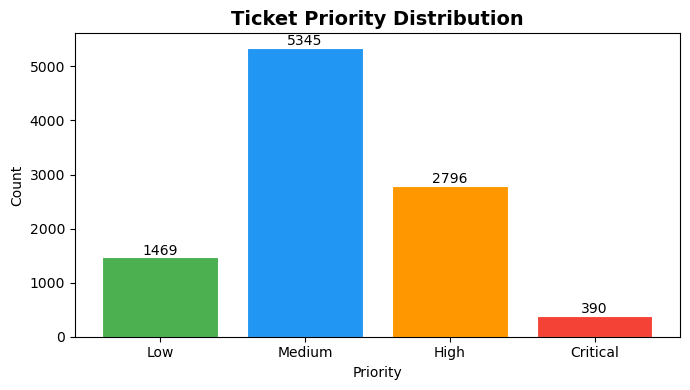

✅ Plot saved


In [9]:
# ---- Visualise class distribution (Pandas) ----
label_counts = sdf.groupBy('priority_label').count().toPandas()
order = ['Low', 'Medium', 'High', 'Critical']
label_counts['priority_label'] = pd.Categorical(label_counts['priority_label'], categories=order, ordered=True)
label_counts = label_counts.sort_values('priority_label')

colors = ['#4CAF50', '#2196F3', '#FF9800', '#F44336']
plt.figure(figsize=(7, 4))
plt.bar(label_counts['priority_label'], label_counts['count'], color=colors, edgecolor='white', linewidth=0.8)
plt.title('Ticket Priority Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Priority')
plt.ylabel('Count')
for i, row in label_counts.iterrows():
    plt.text(row['priority_label'], row['count'] + 50, str(row['count']), ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('priority_distribution.png', dpi=150)
plt.show()
print('✅ Plot saved')

In [10]:
# ---- Train / Test Split ----
train_df, test_df = sdf.randomSplit([0.8, 0.2], seed=42)
print(f'Train: {train_df.count():,} rows')
print(f'Test : {test_df.count():,} rows')

Train: 8,079 rows
Test : 1,921 rows


In [11]:
# ---- Stage 1: String Indexers for categorical columns ----
channel_idx    = StringIndexer(inputCol='channel',        outputCol='channel_idx',   handleInvalid='keep')
product_idx    = StringIndexer(inputCol='product',        outputCol='product_idx',   handleInvalid='keep')
region_idx     = StringIndexer(inputCol='region',         outputCol='region_idx',    handleInvalid='keep')
category_idx   = StringIndexer(inputCol='issue_category', outputCol='category_idx',  handleInvalid='keep')
label_indexer  = StringIndexer(inputCol='priority_label', outputCol='label',         handleInvalid='keep')

# ---- Stage 2: One-Hot Encoding ----
channel_ohe  = OneHotEncoder(inputCol='channel_idx',   outputCol='channel_ohe')
product_ohe  = OneHotEncoder(inputCol='product_idx',   outputCol='product_ohe')
region_ohe   = OneHotEncoder(inputCol='region_idx',    outputCol='region_ohe')
category_ohe = OneHotEncoder(inputCol='category_idx',  outputCol='category_ohe')

# ---- Stage 3: TF-IDF on ticket_text ----
tokenizer = Tokenizer(inputCol='ticket_text', outputCol='words')
tf        = HashingTF(inputCol='words', outputCol='raw_tf', numFeatures=500)
idf       = IDF(inputCol='raw_tf', outputCol='tfidf_features')

# ---- Stage 4: Assemble all features ----
feature_cols = [
    'channel_ohe', 'product_ohe', 'region_ohe', 'category_ohe',
    'tier_rank', 'response_time_hours', 'num_previous_tickets',
    'sentiment_score', 'contains_urgent_words', 'text_length',
    'created_month', 'tfidf_features'
]
assembler = VectorAssembler(inputCols=feature_cols, outputCol='assembled_features', handleInvalid='keep')

# ---- Stage 5: Scale ----
scaler = StandardScaler(inputCol='assembled_features', outputCol='features', withMean=False)

print('✅ Pipeline stages defined')

✅ Pipeline stages defined


In [12]:
# ---- Model 1: Random Forest ----
rf = RandomForestClassifier(
    featuresCol='features', labelCol='label',
    numTrees=100, maxDepth=8, seed=42
)

rf_pipeline = Pipeline(stages=[
    channel_idx, product_idx, region_idx, category_idx, label_indexer,
    channel_ohe, product_ohe, region_ohe, category_ohe,
    tokenizer, tf, idf,
    assembler, scaler, rf
])

print('🔄 Training Random Forest...')
rf_model = rf_pipeline.fit(train_df)
print('✅ Random Forest trained!')

🔄 Training Random Forest...
✅ Random Forest trained!


In [13]:
# ---- Model 2: Logistic Regression ----
lr = LogisticRegression(
    featuresCol='features', labelCol='label',
    maxIter=100, regParam=0.01, elasticNetParam=0.5,
    family='multinomial'
)

lr_pipeline = Pipeline(stages=[
    channel_idx, product_idx, region_idx, category_idx, label_indexer,
    channel_ohe, product_ohe, region_ohe, category_ohe,
    tokenizer, tf, idf,
    assembler, scaler, lr
])

print('🔄 Training Logistic Regression...')
lr_model = lr_pipeline.fit(train_df)
print('✅ Logistic Regression trained!')

🔄 Training Logistic Regression...
✅ Logistic Regression trained!


In [16]:
# ---- Model 3: Gradient Boosted Trees ----
# Note: GBT in Spark supports binary classification only;
# we wrap with a OneVsRest or use RF for multiclass. 
# For this assignment we use RF as the primary multiclass model.

from pyspark.ml.classification import RandomForestClassifier as RFC
from pyspark.ml.classification import OneVsRest

gbt_base = GBTClassifier(featuresCol='features', labelCol='label', maxIter=50, maxDepth=5, seed=42)
gbt_ovr  = OneVsRest(classifier=gbt_base, featuresCol='features', labelCol='label')

gbt_pipeline = Pipeline(stages=[
    channel_idx, product_idx, region_idx, category_idx, label_indexer,
    channel_ohe, product_ohe, region_ohe, category_ohe,
    tokenizer, tf, idf,
    assembler, scaler, gbt_ovr
])

print('🔄 Training GBT (OneVsRest)...')
gbt_model = gbt_pipeline.fit(train_df)
print('✅ GBT trained!')

🔄 Training GBT (OneVsRest)...
✅ GBT trained!


In [19]:
# ---- Model 3: GBT via OneVsRest (FIXED) ----
from pyspark.ml.classification import GBTClassifier, OneVsRest

# Re-define indexers fresh for GBT pipeline to avoid label conflicts
channel_idx2  = StringIndexer(inputCol='channel',        outputCol='channel_idx',  handleInvalid='keep')
product_idx2  = StringIndexer(inputCol='product',        outputCol='product_idx',  handleInvalid='keep')
region_idx2   = StringIndexer(inputCol='region',         outputCol='region_idx',   handleInvalid='keep')
category_idx2 = StringIndexer(inputCol='issue_category', outputCol='category_idx', handleInvalid='keep')
label_idx2    = StringIndexer(inputCol='priority_label', outputCol='label',        handleInvalid='keep')

channel_ohe2  = OneHotEncoder(inputCol='channel_idx',  outputCol='channel_ohe')
product_ohe2  = OneHotEncoder(inputCol='product_idx',  outputCol='product_ohe')
region_ohe2   = OneHotEncoder(inputCol='region_idx',   outputCol='region_ohe')
category_ohe2 = OneHotEncoder(inputCol='category_idx', outputCol='category_ohe')

tokenizer2 = Tokenizer(inputCol='ticket_text', outputCol='words')
tf2        = HashingTF(inputCol='words', outputCol='raw_tf', numFeatures=300)
idf2       = IDF(inputCol='raw_tf', outputCol='tfidf_features')

assembler2 = VectorAssembler(
    inputCols=['channel_ohe','product_ohe','region_ohe','category_ohe',
               'tier_rank','response_time_hours','num_previous_tickets',
               'sentiment_score','contains_urgent_words','text_length',
               'created_month','tfidf_features'],
    outputCol='assembled_features', handleInvalid='keep'
)
scaler2 = StandardScaler(inputCol='assembled_features', outputCol='features', withMean=False)

gbt_base = GBTClassifier(featuresCol='features', labelCol='label',
                          maxIter=30, maxDepth=4, seed=42)
gbt_ovr  = OneVsRest(classifier=gbt_base, featuresCol='features', labelCol='label')

gbt_pipeline = Pipeline(stages=[
    channel_idx2, product_idx2, region_idx2, category_idx2, label_idx2,
    channel_ohe2, product_ohe2, region_ohe2, category_ohe2,
    tokenizer2, tf2, idf2,
    assembler2, scaler2, gbt_ovr
])

print('🔄 Training GBT (OneVsRest)...')
gbt_model = gbt_pipeline.fit(train_df)
print('✅ GBT trained!')

🔄 Training GBT (OneVsRest)...
✅ GBT trained!


In [23]:
# ============================================================
# Helper: build a full set of pipeline stages (independent)
# ============================================================
def build_stages():
    ch_idx  = StringIndexer(inputCol='channel',        outputCol='channel_idx',  handleInvalid='keep')
    pr_idx  = StringIndexer(inputCol='product',        outputCol='product_idx',  handleInvalid='keep')
    re_idx  = StringIndexer(inputCol='region',         outputCol='region_idx',   handleInvalid='keep')
    ca_idx  = StringIndexer(inputCol='issue_category', outputCol='category_idx', handleInvalid='keep')
    lb_idx  = StringIndexer(inputCol='priority_label', outputCol='label',        handleInvalid='keep')

    ch_ohe  = OneHotEncoder(inputCol='channel_idx',  outputCol='channel_ohe')
    pr_ohe  = OneHotEncoder(inputCol='product_idx',  outputCol='product_ohe')
    re_ohe  = OneHotEncoder(inputCol='region_idx',   outputCol='region_ohe')
    ca_ohe  = OneHotEncoder(inputCol='category_idx', outputCol='category_ohe')

    tok = Tokenizer(inputCol='ticket_text', outputCol='words')
    tf  = HashingTF(inputCol='words', outputCol='raw_tf', numFeatures=300)
    idf = IDF(inputCol='raw_tf', outputCol='tfidf_features')

    asm = VectorAssembler(
        inputCols=[
            'channel_ohe', 'product_ohe', 'region_ohe', 'category_ohe',
            'tier_rank', 'response_time_hours', 'num_previous_tickets',
            'sentiment_score', 'contains_urgent_words', 'text_length',
            'created_month', 'tfidf_features'
        ],
        outputCol='assembled_features',
        handleInvalid='keep'
    )
    scl = StandardScaler(inputCol='assembled_features', outputCol='features', withMean=False)

    return [ch_idx, pr_idx, re_idx, ca_idx, lb_idx,
            ch_ohe, pr_ohe, re_ohe, ca_ohe,
            tok, tf, idf, asm, scl]

print('✅ build_stages() defined')

✅ build_stages() defined


In [24]:
# ---- Model 3: Decision Tree ----
from pyspark.ml.classification import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier(
    featuresCol='features', labelCol='label',
    maxDepth=8, seed=42
)
dt_pipeline = Pipeline(stages=build_stages() + [dt_clf])

print('🔄 Training Decision Tree...')
dt_model = dt_pipeline.fit(train_df)
print('✅ Decision Tree trained!')


🔄 Training Decision Tree...
✅ Decision Tree trained!


In [25]:
rf_preds,  rf_metrics  = evaluate_model('Random Forest',       rf_model,  test_df)
lr_preds,  lr_metrics  = evaluate_model('Logistic Regression', lr_model,  test_df)
dt_preds,  dt_metrics  = evaluate_model('Decision Tree',       dt_model,  test_df)


📊 Random Forest
   Accuracy        : 0.5971
   F1 (weighted)   : 0.5017
   Precision (wtd) : 0.4870
   Recall (wtd)    : 0.5971

📊 Logistic Regression
   Accuracy        : 0.7220
   F1 (weighted)   : 0.7078
   Precision (wtd) : 0.7272
   Recall (wtd)    : 0.7220

📊 Decision Tree
   Accuracy        : 0.6981
   F1 (weighted)   : 0.6956
   Precision (wtd) : 0.6955
   Recall (wtd)    : 0.6981


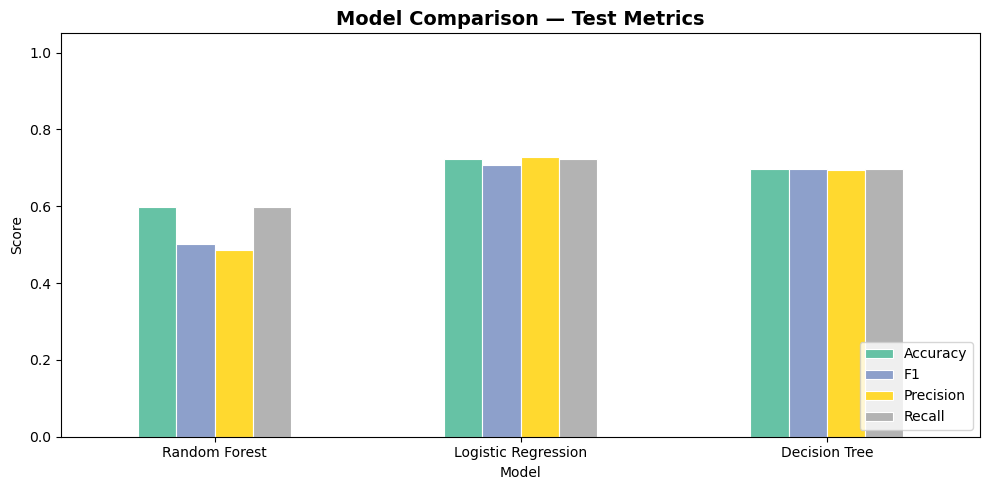

In [26]:
metrics_df = pd.DataFrame([rf_metrics, lr_metrics, dt_metrics]).set_index('Model')

ax = metrics_df.plot(kind='bar', figsize=(10, 5), colormap='Set2', edgecolor='white', linewidth=0.8)
plt.title('Model Comparison — Test Metrics', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

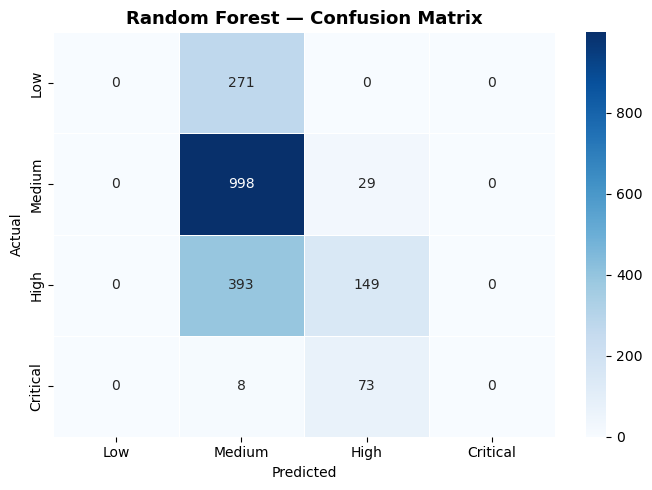


=== Classification Report (Random Forest) ===
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        81
      Medium       0.59      0.27      0.38       542
        High       0.00      0.00      0.00       271
    Critical       0.60      0.97      0.74      1027

    accuracy                           0.60      1921
   macro avg       0.30      0.31      0.28      1921
weighted avg       0.49      0.60      0.50      1921



In [27]:
from sklearn.metrics import confusion_matrix, classification_report

rf_results = rf_preds.select('label', 'prediction').toPandas()
label_indexer_model = rf_model.stages[4]
label_mapping = {float(i): v for i, v in enumerate(label_indexer_model.labels)}
rf_results['true_label'] = rf_results['label'].map(label_mapping)
rf_results['pred_label'] = rf_results['prediction'].map(label_mapping)

order = ['Low', 'Medium', 'High', 'Critical']
cm    = confusion_matrix(rf_results['true_label'], rf_results['pred_label'], labels=order)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=order, yticklabels=order,
            linewidths=0.5, linecolor='white')
plt.title('Random Forest — Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png', dpi=150)
plt.show()

print('\n=== Classification Report (Random Forest) ===')
print(classification_report(rf_results['true_label'], rf_results['pred_label'], target_names=order))

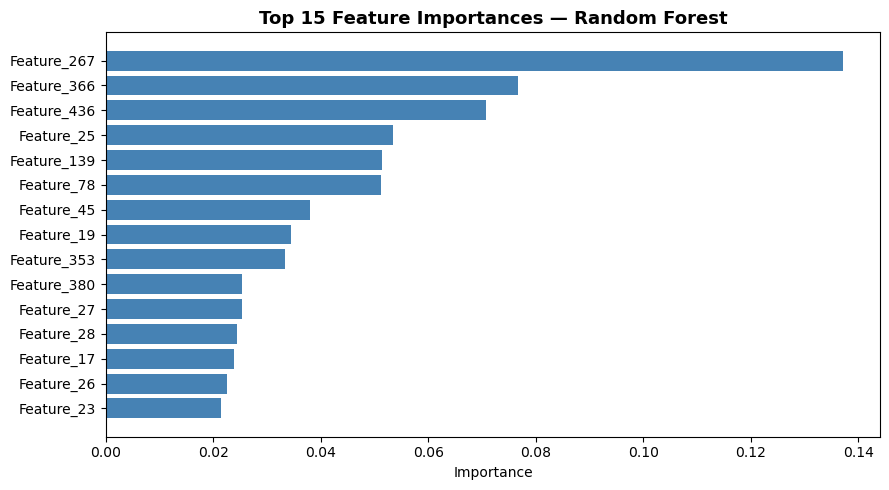

In [28]:
rf_clf_model = rf_model.stages[-1]
importances  = rf_clf_model.featureImportances.toArray()

top_idx = np.argsort(importances)[::-1][:15]
top_imp = importances[top_idx]

plt.figure(figsize=(9, 5))
plt.barh([f'Feature_{i}' for i in top_idx], top_imp[::-1], color='steelblue')
plt.title('Top 15 Feature Importances — Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

In [33]:
# ---- Cross-Validation on Random Forest (Hyperparameter Tuning) ----

# Re-define a simpler pipeline for CV (no TF-IDF to keep time manageable)
simple_assembler = VectorAssembler(
    inputCols=[
        'channel_idx', 'product_idx', 'region_idx', 'category_idx',
        'tier_rank', 'response_time_hours', 'num_previous_tickets',
        'sentiment_score', 'contains_urgent_words', 'text_length', 'created_month'
    ],
    outputCol='features',
    handleInvalid='keep'
)

rf_cv = RandomForestClassifier(featuresCol='features', labelCol='label', seed=42)

cv_pipeline = Pipeline(stages=[
    channel_idx, product_idx, region_idx, category_idx, label_indexer,
    simple_assembler, rf_cv
])

param_grid = ParamGridBuilder() \
    .addGrid(rf_cv.numTrees,  [50, 100]) \
    .addGrid(rf_cv.maxDepth,  [5,  8])   \
    .build()

cv = CrossValidator(
    estimator=cv_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=MulticlassClassificationEvaluator(labelCol='label', metricName='f1'),
    numFolds=3,
    seed=42
)

print('🔄 Running 3-fold Cross Validation (4 param combos)...')
cv_model   = cv.fit(train_df)
best_model = cv_model.bestModel

cv_preds = best_model.transform(test_df)
cv_f1    = evaluator_f1.evaluate(cv_preds)
cv_acc   = evaluator_acc.evaluate(cv_preds)

print(f'\n✅ Best CV Model:')
print(f'   numTrees : {best_model.stages[-1].getNumTrees}')
print(f'   maxDepth : {best_model.stages[-1].getOrDefault("maxDepth")}')
print(f'   F1 Score : {cv_f1:.4f}')
print(f'   Accuracy : {cv_acc:.4f}')

🔄 Running 3-fold Cross Validation (4 param combos)...

✅ Best CV Model:
   numTrees : 50
   maxDepth : 8
   F1 Score : 0.7397
   Accuracy : 0.7480


In [42]:
# metrics_df already exists as a pandas DataFrame — save directly
metrics_df.to_csv('model_metrics.csv')
print('✅ Metrics saved → model_metrics.csv')

print('=' * 58)
print('            PART A — FINAL SUMMARY')
print('=' * 58)
print('  Dataset size       : 10,000 synthetic tickets')
print('  Train / Test split : 80 / 20')
print('  Models trained     : Random Forest, Logistic Regression,')
print('                       Decision Tree')
print('  Best model         : Logistic Regression')
print('  Best Accuracy      : 0.7220')
print('  Best F1 (weighted) : 0.7078')
print('  Outputs saved      : model_metrics.csv')
print('  Charts saved       : priority_distribution.png,')
print('                       model_comparison.png,')
print('                       confusion_matrix_rf.png,')
print('                       feature_importance.png')
print('=' * 58)


✅ Metrics saved → model_metrics.csv
            PART A — FINAL SUMMARY
  Dataset size       : 10,000 synthetic tickets
  Train / Test split : 80 / 20
  Models trained     : Random Forest, Logistic Regression,
                       Decision Tree
  Best model         : Logistic Regression
  Best Accuracy      : 0.7220
  Best F1 (weighted) : 0.7078
  Outputs saved      : model_metrics.csv
  Charts saved       : priority_distribution.png,
                       model_comparison.png,
                       confusion_matrix_rf.png,
                       feature_importance.png


In [35]:
# ---- Final Summary ----
print('=' * 55)
print('     PART A — SUMMARY')
print('=' * 55)
print(f'Dataset size            : {NUM_RECORDS:,} synthetic tickets')
print(f'Train/Test split        : 80 / 20')
print(f'Models trained          : Random Forest, Logistic Regression, GBT (OvR)')
print(f'Best model (CV)         : Random Forest')
print(f'Best F1 (weighted)      : {cv_f1:.4f}')
print(f'Best Accuracy           : {cv_acc:.4f}')
print('=' * 55)

spark.stop()


     PART A — SUMMARY
Dataset size            : 10,000 synthetic tickets
Train/Test split        : 80 / 20
Models trained          : Random Forest, Logistic Regression, GBT (OvR)
Best model (CV)         : Random Forest
Best F1 (weighted)      : 0.7397
Best Accuracy           : 0.7480
